# Corn Belt point data: exploratory data analysis

First point: Ames, Iowa (`42.03°N, 93.47°W`), using the Corn Belt reference site already present in the repository. This notebook explores the point-level exports from NASA POWER, SMAP, GLDAS, and IGBP-DIS.

The common analysis window is 2015-03-31 through 2025-12-31: NASA POWER is daily and SMAP is 3-hourly (the product begins on 2015-03-31). A daily integrated table averages SMAP to UTC days and attaches GLDAS/IGBP as static soil context. The original longer POWER series and 2024-only SMAP extract are retained separately. These regional products are not field measurements.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data_corn_belt').is_dir())
DATA = ROOT / 'src' / 'data_corn_belt'
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

FILES = {
    'POWER': DATA / 'power_ames_2015_2025.csv',
    'SMAP': DATA / 'smap_ames_2015_2025.csv',
    'GLDAS soils': DATA / 'gldas_soils_ames.csv',
    'IGBP soils': DATA / 'igbp_soils_ames.csv',
    'Integrated daily': DATA / 'corn_belt_daily_2015_2025.csv',
}
for source, path in FILES.items():
    print(f'{source:12} | {"ready" if path.exists() else "missing":7} | {path.name}')

POWER        | ready   | power_ames_2015_2025.csv
SMAP         | ready   | smap_ames_2015_2025.csv
GLDAS soils  | ready   | gldas_soils_ames.csv
IGBP soils   | ready   | igbp_soils_ames.csv
Integrated daily | ready   | corn_belt_daily_2015_2025.csv


## 1. NASA POWER — daily weather

POWER provides daily point estimates. The downloaded columns include mean, maximum and minimum air temperature, corrected precipitation, relative humidity, wind speed, and downward shortwave radiation. `T2M` is in °C, `PRECTOTCORR` in mm/day, `RH2M` in %, `WS2M` in m/s, and `ALLSKY_SFC_SW_DWN` in MJ/m²/day. The requested time standard is UTC.

In [2]:
power = pd.read_csv(FILES['POWER'], index_col=0, parse_dates=True).sort_index() if FILES['POWER'].exists() else None
if power is None:
    print('POWER CSV is missing. Download it using the command in src/data_corn_belt/README.md.')
else:
    power.index.name = 'date'
    print('Shape:', power.shape, '| Dates:', power.index.min().date(), 'to', power.index.max().date())
    display(power.head())
    display(pd.DataFrame({'missing': power.isna().sum(), 'missing_pct': (100 * power.isna().mean()).round(2), 'dtype': power.dtypes.astype(str)}))
    display(power.describe().T.round(2))

Shape: (3929, 7) | Dates: 2015-03-31 to 2025-12-31


,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M,ALLSKY_SFC_SW_DWN
date,,,,,,,
2015-03-31,12.74,21.80,2.72,0.00,60.46,3.13,22.54
2015-04-01,15.41,25.00,7.30,0.00,56.45,5.06,22.54
2015-04-02,14.65,20.18,7.66,12.44,67.38,4.41,19.22
2015-04-03,6.24,12.90,0.84,0.33,52.79,5.18,22.19
2015-04-04,5.49,17.58,-2.11,0.00,53.26,3.50,23.67


,missing,missing_pct,dtype
T2M,0,0.0,float64
T2M_MAX,0,0.0,float64
T2M_MIN,0,0.0,float64
PRECTOTCORR,0,0.0,float64
RH2M,0,0.0,float64
WS2M,0,0.0,float64
ALLSKY_SFC_SW_DWN,0,0.0,float64


,count,mean,std,min,25%,50%,75%,max
T2M,3929.0,10.48,11.75,-25.98,0.92,11.48,21.24,31.58
T2M_MAX,3929.0,16.50,12.16,-20.47,6.35,18.67,27.22,40.22
T2M_MIN,3929.0,5.58,11.23,-32.88,-2.83,5.92,15.62,27.35
PRECTOTCORR,3929.0,2.31,5.51,0.00,0.00,0.08,1.58,55.99
RH2M,3929.0,73.97,12.39,36.42,65.37,75.17,83.36,99.63
WS2M,3929.0,3.29,1.43,0.61,2.23,3.05,4.09,10.80
ALLSKY_SFC_SW_DWN,3929.0,14.62,7.89,0.82,8.08,13.74,21.17,31.92


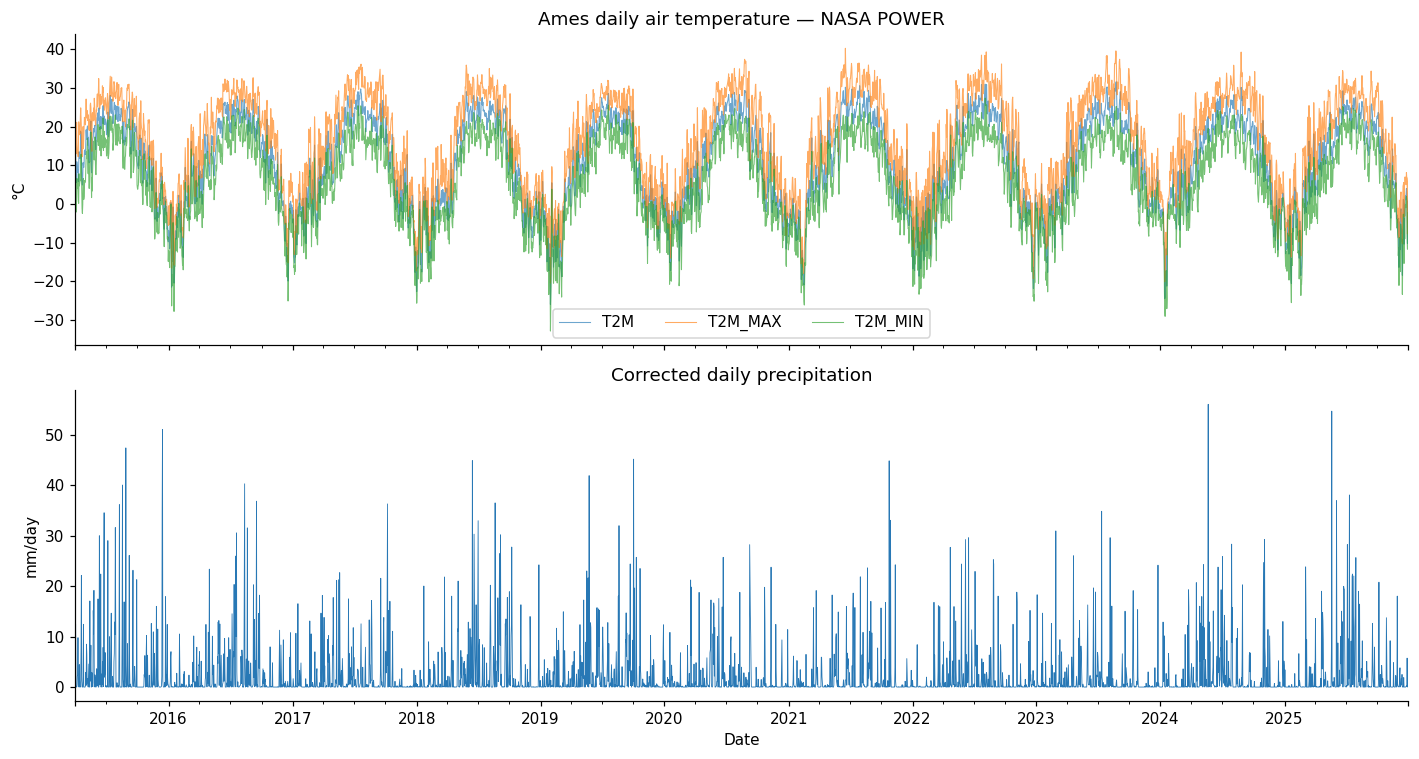

In [3]:
if power is not None:
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    power[['T2M', 'T2M_MAX', 'T2M_MIN']].plot(ax=axes[0], alpha=0.65, linewidth=0.7)
    axes[0].set(title='Ames daily air temperature — NASA POWER', ylabel='°C')
    axes[0].legend(ncol=3)
    power['PRECTOTCORR'].plot(ax=axes[1], color='#2878B5', linewidth=0.55)
    axes[1].set(title='Corrected daily precipitation', ylabel='mm/day', xlabel='Date')
    plt.tight_layout()
else:
    print('POWER charts skipped: CSV not available.')

,T2M,PRECTOTCORR
month,,
1,-6.48,0.97
2,-3.88,0.87
3,3.49,1.85
4,9.37,2.13
5,16.36,3.58
6,22.74,3.86
7,24.40,3.33
8,23.16,3.16
9,19.96,2.69


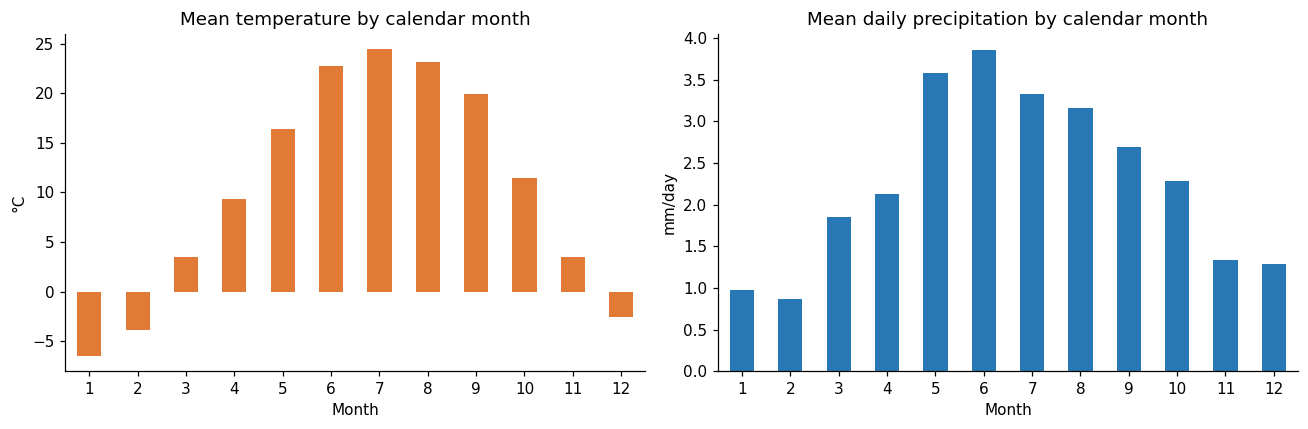

In [4]:
if power is not None:
    power_monthly = power[['T2M', 'PRECTOTCORR']].groupby(power.index.month).agg({'T2M': 'mean', 'PRECTOTCORR': 'mean'})
    power_monthly.index.name = 'month'
    display(power_monthly.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    power_monthly['T2M'].plot(kind='bar', ax=axes[0], color='#E07A35', rot=0)
    axes[0].set(title='Mean temperature by calendar month', xlabel='Month', ylabel='°C')
    power_monthly['PRECTOTCORR'].plot(kind='bar', ax=axes[1], color='#2878B5', rot=0)
    axes[1].set(title='Mean daily precipitation by calendar month', xlabel='Month', ylabel='mm/day')
    plt.tight_layout()
else:
    print('POWER monthly summaries skipped: CSV not available.')

## 2. SMAP L4 — soil moisture and surface temperature

SMAP values represent the nearest 9 km pixel to Ames, sampled every three hours in UTC. The table contains surface moisture (0–5 cm), root-zone moisture (0–100 cm), profile moisture, and land-surface temperature. The satellite product is model-assimilated and regional; it is useful for temporal patterns and comparison, not as a direct field sensor.

In [5]:
smap = pd.read_csv(FILES['SMAP'], index_col=0, parse_dates=True).sort_index() if FILES['SMAP'].exists() else None
if smap is None:
    print('SMAP CSV is missing. Earthdata login is required; see src/data_corn_belt/README.md.')
else:
    smap.index.name = 'datetime_utc'
    print('Shape:', smap.shape, '| Times:', smap.index.min(), 'to', smap.index.max())
    print('Median interval:', smap.index.to_series().diff().median())
    display(smap.head())
    display(pd.DataFrame({'missing': smap.isna().sum(), 'missing_pct': (100 * smap.isna().mean()).round(2)}))
    display(smap.describe().T.round(3))

Shape: (31432, 4) | Times: 2015-03-31 01:30:00 to 2025-12-31 22:30:00
Median interval: 0 days 03:00:00


,sm_surface,sm_rootzone,sm_profile,surface_temp
datetime_utc,,,,
2015-03-31 01:30:00,0.256847,0.311406,0.332752,286.474
2015-03-31 04:30:00,0.258706,0.311323,0.332631,283.530
2015-03-31 07:30:00,0.261149,0.311383,0.332539,280.207
2015-03-31 10:30:00,0.264804,0.311322,0.332587,277.491
2015-03-31 13:30:00,0.268393,0.311391,0.332507,280.225


,missing,missing_pct
sm_surface,0,0.0
sm_rootzone,0,0.0
sm_profile,0,0.0
surface_temp,0,0.0


,count,mean,std,min,25%,50%,75%,max
sm_surface,31432.0,0.263,0.063,0.074,0.221,0.261,0.314,0.450
sm_rootzone,31432.0,0.287,0.042,0.198,0.255,0.286,0.322,0.401
sm_profile,31432.0,0.305,0.047,0.210,0.268,0.303,0.342,0.425
surface_temp,31432.0,282.822,12.450,238.077,272.879,284.208,293.348,309.308


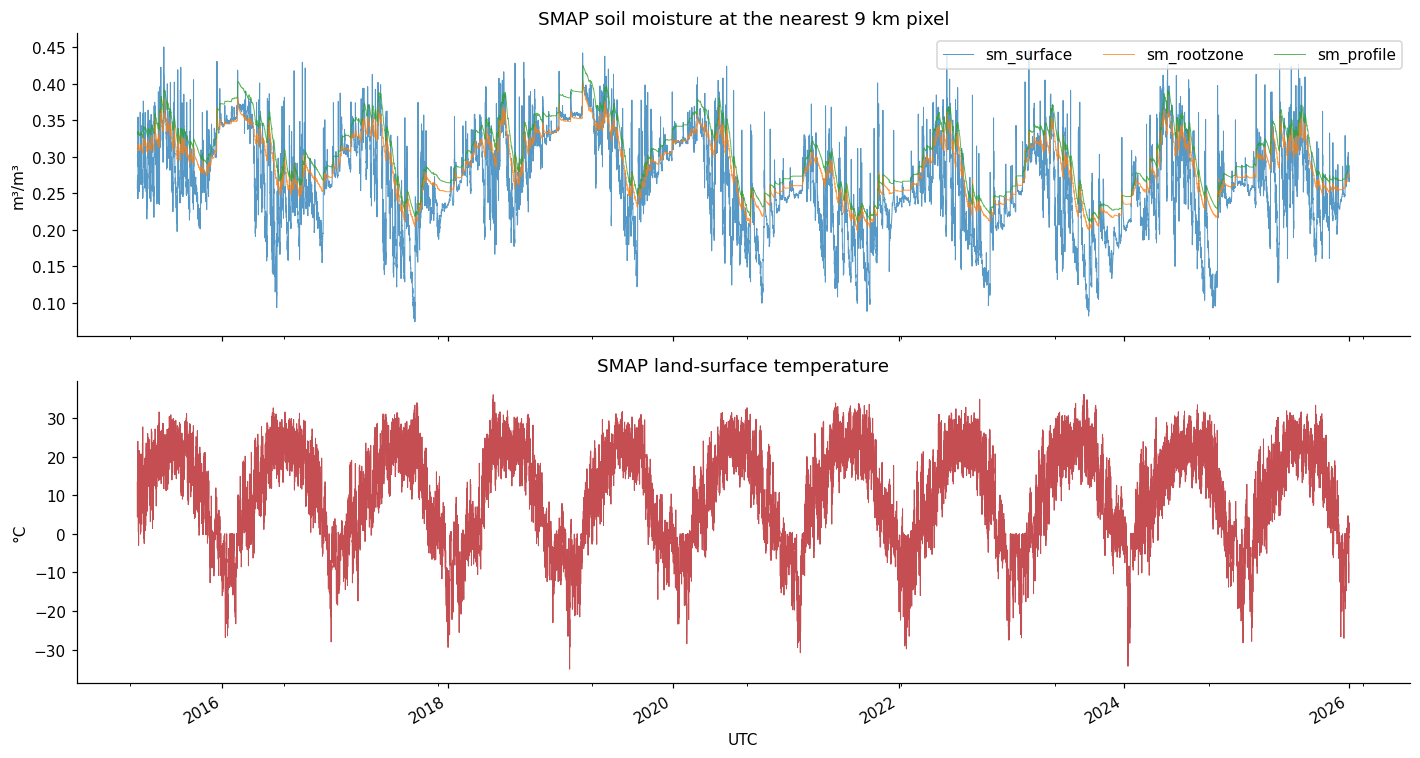

In [6]:
if smap is not None:
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    moisture_cols = [c for c in ['sm_surface', 'sm_rootzone', 'sm_profile'] if c in smap.columns]
    smap[moisture_cols].plot(ax=axes[0], linewidth=0.65, alpha=0.75)
    axes[0].set(title='SMAP soil moisture at the nearest 9 km pixel', ylabel='m³/m³')
    axes[0].legend(ncol=3)
    if 'surface_temp' in smap:
        (smap['surface_temp'] - 273.15).plot(ax=axes[1], color='#C44E52', linewidth=0.65)
        axes[1].set(title='SMAP land-surface temperature', ylabel='°C', xlabel='UTC')
    else:
        axes[1].text(0.5, 0.5, 'surface_temp not present in this export', ha='center', va='center', transform=axes[1].transAxes)
        axes[1].set_axis_off()
    plt.tight_layout()
else:
    print('SMAP plots skipped: CSV not available.')

## 3. GLDAS — soil texture fractions and porosity

GLDAS supplies static values from the nearest 0.25° cell. Texture class is categorical; sand, silt, clay, and porosity are unitless fractions. Check the reported source-cell coordinates before interpreting the values.

site,Ames
lat,42.03
lon,-93.47
grid_lat,42.125
grid_lon,-93.375
texture_class,6
texture,Loam
sand,0.4
silt,0.36
clay,0.24
porosity,0.437


Sand + silt + clay: [1.0]


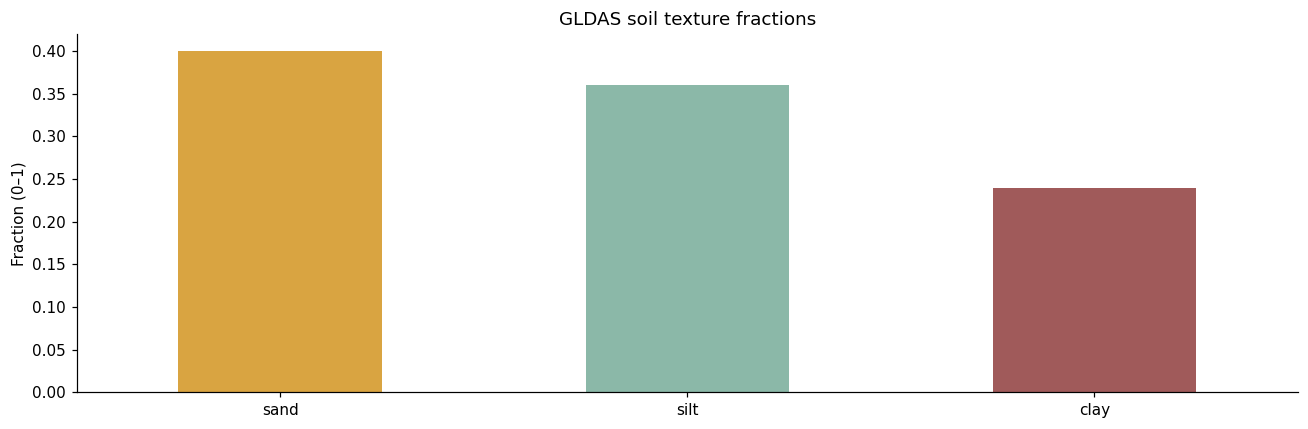

In [7]:
gldas = pd.read_csv(FILES['GLDAS soils'], index_col=0) if FILES['GLDAS soils'].exists() else None
if gldas is None:
    print('GLDAS CSV is missing.')
else:
    display(gldas.T.rename(columns={gldas.index[0]: 'Ames'}))
    fraction_cols = [c for c in ['sand', 'silt', 'clay'] if c in gldas.columns]
    if fraction_cols:
        ax = gldas[fraction_cols].iloc[0].plot(kind='bar', color=['#D9A441', '#8BB8A8', '#A05A5A'][:len(fraction_cols)])
        ax.set(title='GLDAS soil texture fractions', ylabel='Fraction (0–1)', xlabel='')
        plt.xticks(rotation=0)
        plt.tight_layout()
    print('Sand + silt + clay:', gldas[fraction_cols].sum(axis=1).round(3).tolist() if fraction_cols else 'fractions unavailable')

## 4. IGBP-DIS — static soil properties (0–100 cm)

IGBP-DIS reports hydraulic and chemical soil estimates for a 0–100 cm layer. Field capacity, wilting point, and available water capacity are in mm; bulk density is g/cm³; soil carbon is kg/m²; total nitrogen is g/m². These are static legacy estimates, so use local soil tests when available.

site,Ames
lat,42.030000
lon,-93.470000
field_capacity,419.000000
wilting_point,181.660995
profile_available_water_capacity,237.339005
bulk_density,1.463740
soil_carbon_density,15.427900
total_nitrogen_density,1649.489990
thermal_capacity,1.170280


site,Ames
bulk_density,1.46374
soil_carbon_density,15.42790
total_nitrogen_density,1649.48999


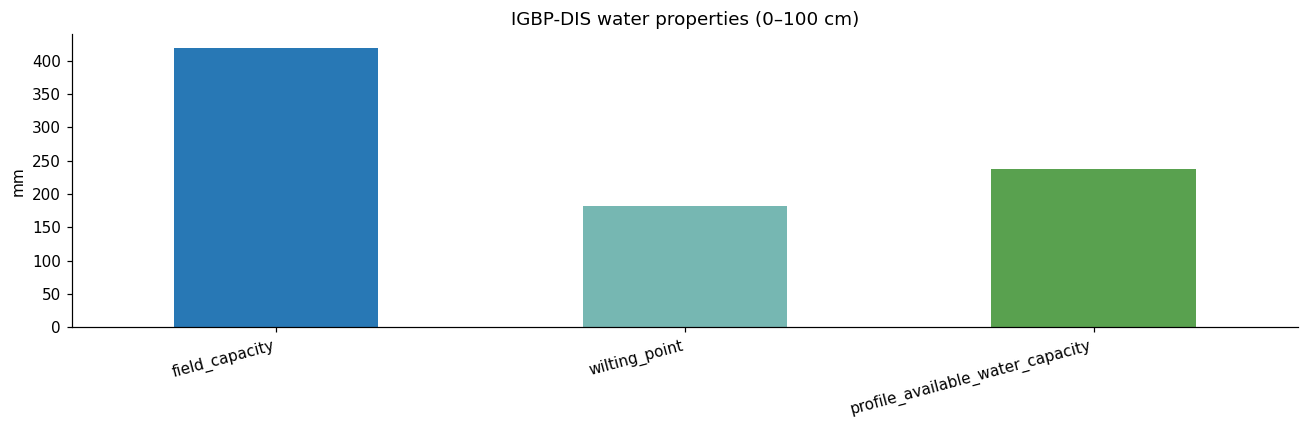

In [8]:
igbp = pd.read_csv(FILES['IGBP soils'], index_col=0) if FILES['IGBP soils'].exists() else None
if igbp is None:
    print('IGBP CSV is missing. Earthdata login is required; see src/data_corn_belt/README.md.')
else:
    display(igbp.T.rename(columns={igbp.index[0]: 'Ames'}))
    water_cols = [c for c in ['field_capacity', 'wilting_point', 'profile_available_water_capacity'] if c in igbp.columns]
    if water_cols:
        ax = igbp[water_cols].iloc[0].plot(kind='bar', color=['#2878B5', '#76B7B2', '#59A14F'][:len(water_cols)])
        ax.set(title='IGBP-DIS water properties (0–100 cm)', ylabel='mm', xlabel='')
        plt.xticks(rotation=15, ha='right')
        plt.tight_layout()
    display(igbp[[c for c in ['bulk_density', 'soil_carbon_density', 'total_nitrogen_density'] if c in igbp.columns]].T.rename(columns={igbp.index[0]: 'Ames'}))

## 5. Cross-source view — POWER precipitation and SMAP root-zone moisture

This overlay uses the full common period (2015-03-31 to 2025-12-31). SMAP is averaged from eight 3-hourly values to each UTC day; POWER precipitation is summed to monthly totals for a readable long-term plot. Rainfall and soil moisture have different units and represent different processes; co-movement does not establish causality or validate either product against ground truth.

Overlapping days: 3929 | Dates: 2015-03-31 to 2025-12-31


,PRECTOTCORR,sm_rootzone
PRECTOTCORR,1.000,0.115
sm_rootzone,0.115,1.000


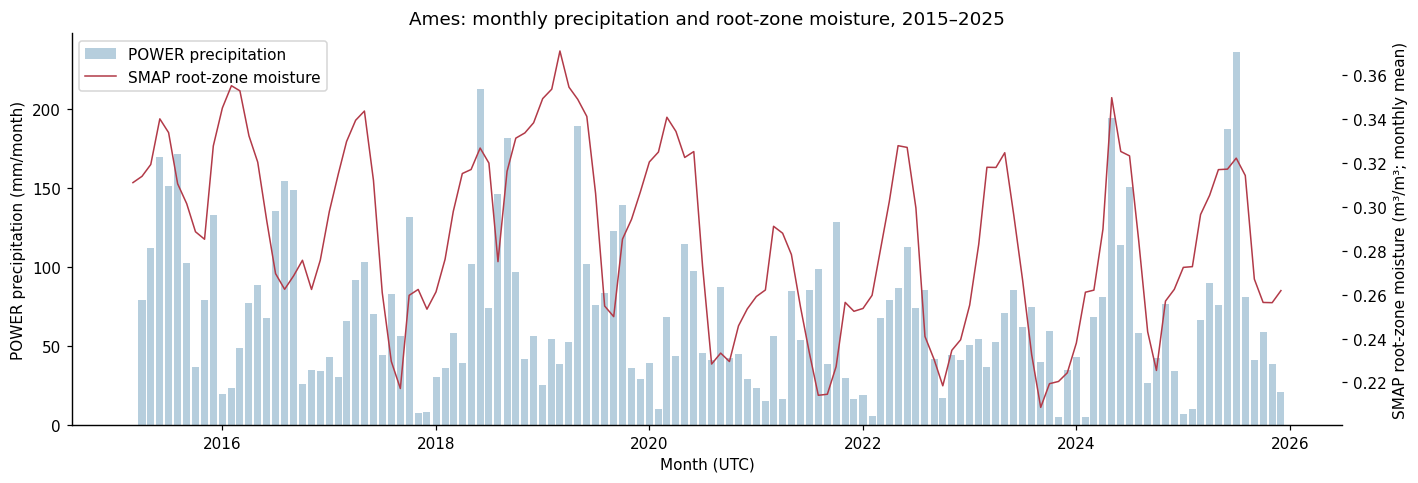

In [9]:
if power is not None and smap is not None:
    power_shared = power.loc['2015-03-31':'2025-12-31', ['PRECTOTCORR']].copy()
    smap_daily = smap[['sm_rootzone']].resample('D').mean()
    comparison = power_shared.join(smap_daily, how='inner').dropna()
    print('Overlapping days:', len(comparison), '| Dates:', comparison.index.min().date(), 'to', comparison.index.max().date())
    if len(comparison):
        monthly = comparison.resample('MS').agg({'PRECTOTCORR': 'sum', 'sm_rootzone': 'mean'})
        fig, ax1 = plt.subplots(figsize=(13, 4.5))
        ax1.bar(monthly.index, monthly['PRECTOTCORR'], color='#7AA6C2', width=24, alpha=0.55, label='POWER precipitation')
        ax1.set_ylabel('POWER precipitation (mm/month)')
        ax2 = ax1.twinx()
        ax2.plot(monthly.index, monthly['sm_rootzone'], color='#B23A48', linewidth=1.0, label='SMAP root-zone moisture')
        ax2.set_ylabel('SMAP root-zone moisture (m³/m³; monthly mean)')
        ax1.set_title('Ames: monthly precipitation and root-zone moisture, 2015–2025')
        ax1.set_xlabel('Month (UTC)')
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2, loc='upper left')
        plt.tight_layout()
        display(comparison.corr().round(3))
    else:
        print('No overlapping non-missing daily observations were found.')
else:
    print('Cross-source comparison skipped until both POWER and SMAP CSVs are available.')

## 6. Integrated daily analysis table

`corn_belt_daily_2015_2025.csv` aligns POWER, daily-mean SMAP, and soil context from 2015-03-31 through 2025-12-31. `smap_n_obs` records the valid 3-hourly SMAP samples used in each daily mean. GLDAS and IGBP columns repeat static estimates, not daily observations.

In [10]:
integrated_path = FILES['Integrated daily']
integrated = pd.read_csv(integrated_path, index_col=0, parse_dates=True).sort_index() if integrated_path.exists() else None
if integrated is None:
    print('Integrated daily CSV is missing.')
else:
    integrated.index.name = 'date_utc'
    print('Shape:', integrated.shape, '| Dates:', integrated.index.min().date(), 'to', integrated.index.max().date())
    print('SMAP valid 3-hourly samples/day:', integrated['smap_n_obs'].min(), 'to', integrated['smap_n_obs'].max())
    display(integrated.head())
    display(pd.DataFrame({'missing': integrated.isna().sum(), 'missing_pct': (100 * integrated.isna().mean()).round(2)}))

Shape: (3929, 27) | Dates: 2015-03-31 to 2025-12-31
SMAP valid 3-hourly samples/day: 8 to 8


,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M,ALLSKY_SFC_SW_DWN,smap_sm_surface,smap_sm_rootzone,smap_sm_profile,...,gldas_silt,gldas_clay,gldas_porosity,igbp_field_capacity,igbp_wilting_point,igbp_profile_available_water_capacity,igbp_bulk_density,igbp_soil_carbon_density,igbp_total_nitrogen_density,igbp_thermal_capacity
date_utc,,,,,,,,,,,,,,,,,,,,,
2015-03-31,12.74,21.80,2.72,0.00,60.46,3.13,22.54,0.259424,0.311001,0.332319,...,0.36,0.24,0.437,419.0,181.660995,237.339005,1.46374,15.4279,1649.48999,1.17028
2015-04-01,15.41,25.00,7.30,0.00,56.45,5.06,22.54,0.265556,0.310246,0.331478,...,0.36,0.24,0.437,419.0,181.660995,237.339005,1.46374,15.4279,1649.48999,1.17028
2015-04-02,14.65,20.18,7.66,12.44,67.38,4.41,19.22,0.298867,0.313552,0.332888,...,0.36,0.24,0.437,419.0,181.660995,237.339005,1.46374,15.4279,1649.48999,1.17028
2015-04-03,6.24,12.90,0.84,0.33,52.79,5.18,22.19,0.296449,0.314315,0.333460,...,0.36,0.24,0.437,419.0,181.660995,237.339005,1.46374,15.4279,1649.48999,1.17028
2015-04-04,5.49,17.58,-2.11,0.00,53.26,3.50,23.67,0.285995,0.312945,0.332770,...,0.36,0.24,0.437,419.0,181.660995,237.339005,1.46374,15.4279,1649.48999,1.17028


,missing,missing_pct
T2M,0,0.0
T2M_MAX,0,0.0
T2M_MIN,0,0.0
PRECTOTCORR,0,0.0
RH2M,0,0.0
WS2M,0,0.0
ALLSKY_SFC_SW_DWN,0,0.0
smap_sm_surface,0,0.0
smap_sm_rootzone,0,0.0
smap_sm_profile,0,0.0


## 7. Estacionalidad y evolución temporal (POWER + SMAP)

La tabla integrada permite comparar tendencias mensuales y ciclos estacionales con las mismas fechas. Temperatura y humedad son promedios mensuales; precipitación es el acumulado del mes. Para el perfil estacional se promedian los meses de cada año y se muestra ±1 desviación estándar entre años. Marzo de 2015 se excluye de ese perfil porque el periodo comienza el día 31; se conserva en las series completas.

T2M       PRECTOTCORR        smap_sm_rootzone      
        mean   std        mean    std             mean   std
month                                                       
1      -6.48  1.63       30.09  13.58             0.29  0.04
2      -3.91  3.83       24.57  18.95             0.30  0.04
3       3.46  2.28       57.48  12.35             0.31  0.03
4       9.37  2.08       63.98  24.34             0.32  0.02
5      16.36  1.66      111.13  42.27             0.32  0.02
6      22.74  1.08      115.67  52.08             0.31  0.03
7      24.40  0.97      103.29  58.71             0.29  0.03
8      23.16  1.44       98.07  41.37             0.26  0.03
9      19.96  1.17       80.79  52.14             0.25  0.04
10     11.49  2.32       70.89  45.09             0.26  0.04
11      3.52  2.35       39.91  23.14             0.26  0.03
12     -2.56  2.19       39.83  33.44             0.27  0.04

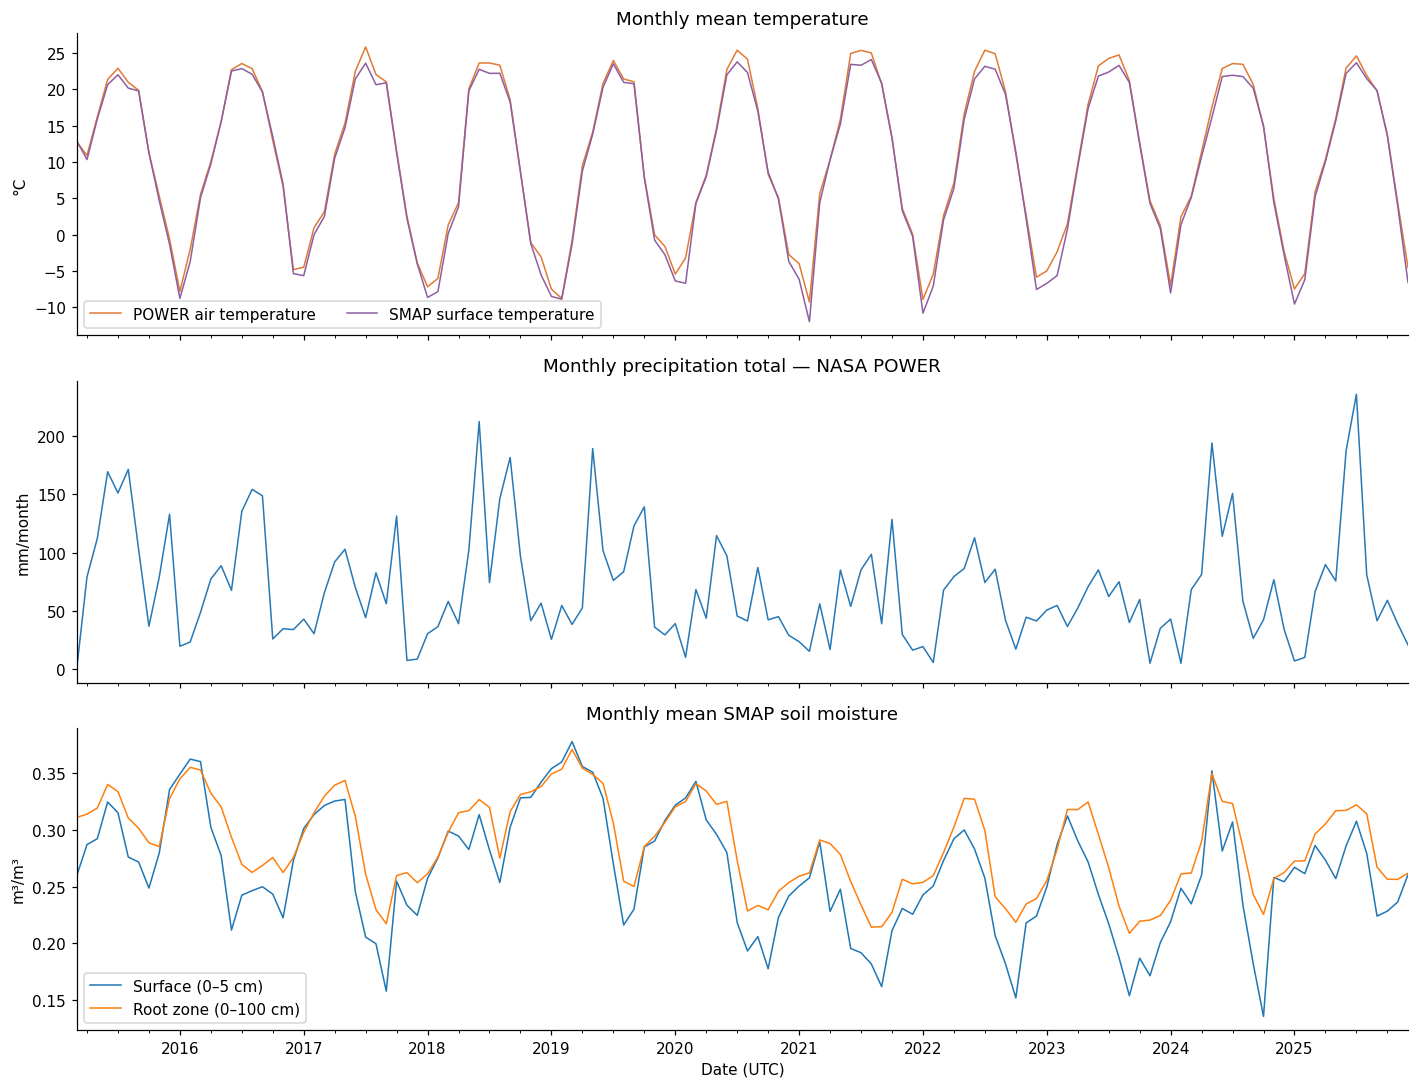

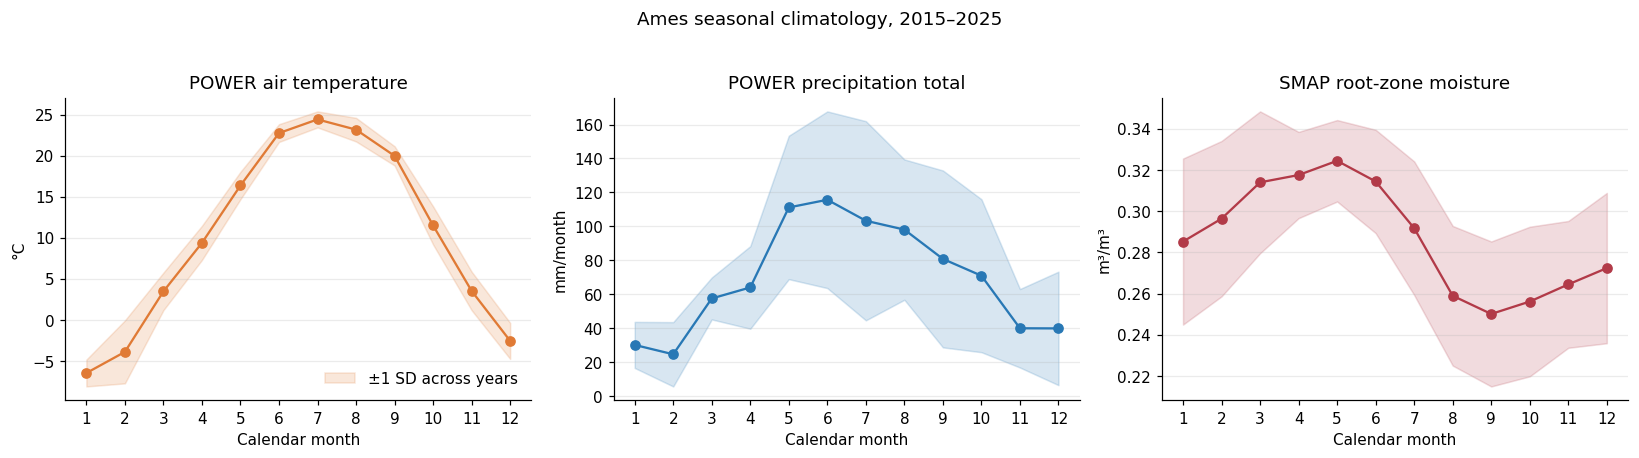

In [11]:
if integrated is not None:
    monthly = integrated.resample('MS').agg({
        'T2M': 'mean',
        'PRECTOTCORR': 'sum',
        'smap_sm_surface': 'mean',
        'smap_sm_rootzone': 'mean',
        'smap_surface_temp': 'mean',
    })

    fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
    monthly['T2M'].plot(ax=axes[0], color='#E07A35', linewidth=1.0, label='POWER air temperature')
    (monthly['smap_surface_temp'] - 273.15).plot(ax=axes[0], color='#8E5EA2', linewidth=1.0, label='SMAP surface temperature')
    axes[0].set(title='Monthly mean temperature', ylabel='°C')
    axes[0].legend(ncol=2)

    monthly['PRECTOTCORR'].plot(ax=axes[1], color='#2878B5', linewidth=1.0)
    axes[1].set(title='Monthly precipitation total — NASA POWER', ylabel='mm/month')

    monthly[['smap_sm_surface', 'smap_sm_rootzone']].plot(ax=axes[2], linewidth=1.0)
    axes[2].set(title='Monthly mean SMAP soil moisture', ylabel='m³/m³', xlabel='Date (UTC)')
    axes[2].legend(['Surface (0–5 cm)', 'Root zone (0–100 cm)'])
    plt.tight_layout()

    monthly_for_climatology = monthly.drop(index=pd.Timestamp('2015-03-01'), errors='ignore').copy()
    monthly_for_climatology['month'] = monthly_for_climatology.index.month
    seasonal = monthly_for_climatology.groupby('month')[['T2M', 'PRECTOTCORR', 'smap_sm_rootzone']].agg(['mean', 'std']).reindex(range(1, 13))
    month_numbers = np.arange(1, 13)
    seasonal_specs = [
        ('T2M', 'POWER air temperature', '°C', '#E07A35'),
        ('PRECTOTCORR', 'POWER precipitation total', 'mm/month', '#2878B5'),
        ('smap_sm_rootzone', 'SMAP root-zone moisture', 'm³/m³', '#B23A48'),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (variable, title, unit, color) in zip(axes, seasonal_specs):
        mean = seasonal[(variable, 'mean')]
        std = seasonal[(variable, 'std')]
        ax.plot(month_numbers, mean, marker='o', color=color)
        ax.fill_between(month_numbers, mean - std, mean + std, color=color, alpha=0.18, label='±1 SD across years')
        ax.set(title=title, xlabel='Calendar month', ylabel=unit, xticks=month_numbers)
        ax.grid(axis='y', alpha=0.25)
    axes[0].legend(frameon=False)
    fig.suptitle('Ames seasonal climatology, 2015–2025', y=1.03)
    plt.tight_layout()
    display(seasonal.round(2))
else:
    print('Seasonality plots skipped: integrated daily CSV is not available.')

## 8. Cruces entre fuentes: temperatura y respuesta de humedad a la lluvia

Primero se comparan temperaturas mensuales de POWER y SMAP (SMAP convertido de K a °C). Después se explora si la precipitación antecedente acompaña cambios de humedad SMAP. Para reducir la correlación que aparece solo porque ambas variables tienen estaciones, se restan sus promedios históricos de cada mes calendario. La curva de desfase usa acumulados de lluvia de 7 días y prueba si la lluvia precede a la humedad entre 0 y 30 días. Es exploratorio: no controla autocorrelación, tendencia, manejo agrícola ni incertidumbre de los productos, por lo que no demuestra causalidad.

,Pearson r
"Monthly temperatures, raw",0.998
After calendar-month adjustment,0.972


,Root-zone moisture,Surface moisture
rainfall leads by (days),,
0,0.348,0.557
1,0.355,0.494
3,0.325,0.373
7,0.299,0.280
14,0.284,0.205
21,0.265,0.187
30,0.271,0.209


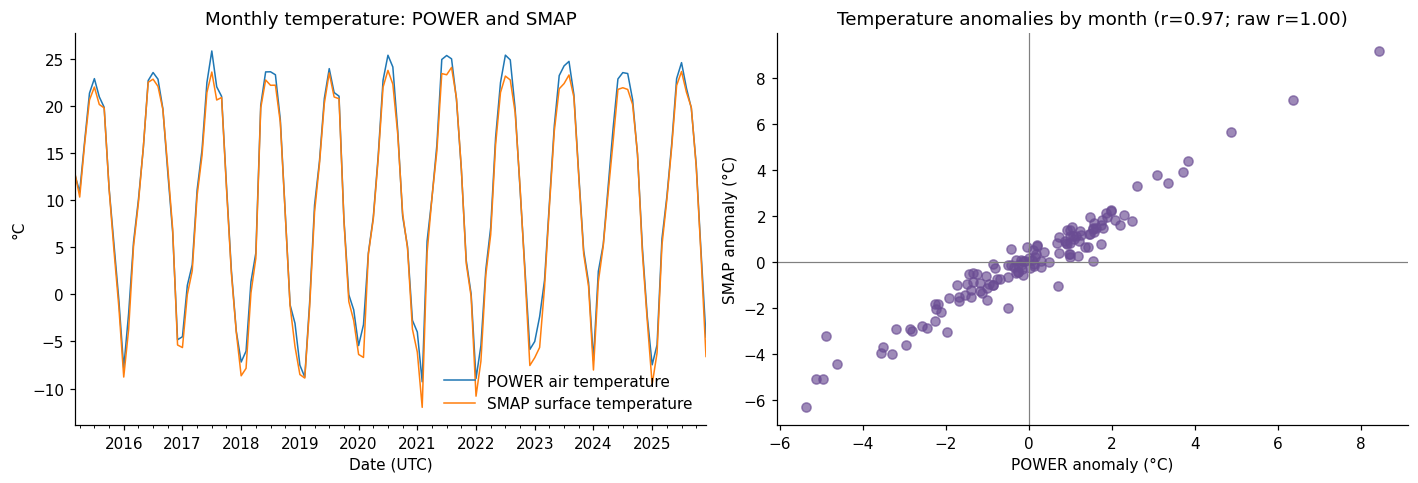

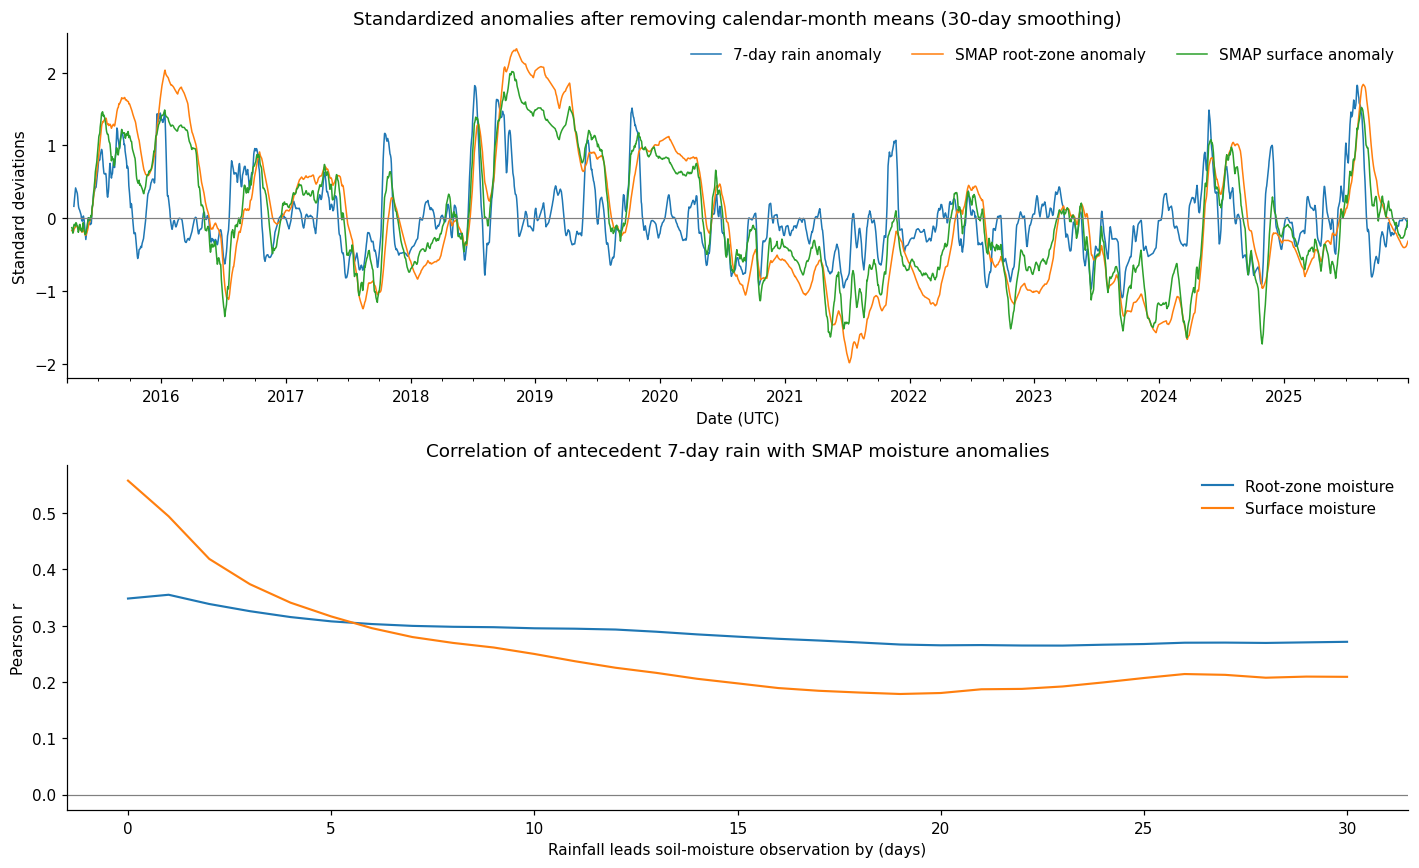

In [12]:
if integrated is not None:
    monthly_temp = integrated[['T2M', 'smap_surface_temp']].resample('MS').mean()
    monthly_temp['smap_surface_temp'] = monthly_temp['smap_surface_temp'] - 273.15
    monthly_temp = monthly_temp.rename(columns={'smap_surface_temp': 'SMAP surface temperature'})
    monthly_temp = monthly_temp.rename(columns={'T2M': 'POWER air temperature'}).dropna()
    temp_anomaly = monthly_temp.copy()
    for column in temp_anomaly.columns:
        temp_anomaly[column] = temp_anomaly[column] - temp_anomaly[column].groupby(temp_anomaly.index.month).transform('mean')
    raw_temp_r = monthly_temp.corr().iloc[0, 1]
    anomaly_temp_r = temp_anomaly.corr().iloc[0, 1]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    monthly_temp.plot(ax=axes[0], linewidth=1.0)
    axes[0].set(title='Monthly temperature: POWER and SMAP', ylabel='°C', xlabel='Date (UTC)')
    axes[0].legend(frameon=False)
    axes[1].scatter(temp_anomaly['POWER air temperature'], temp_anomaly['SMAP surface temperature'], alpha=0.65, color='#6A4C93')
    axes[1].axhline(0, color='grey', linewidth=0.8)
    axes[1].axvline(0, color='grey', linewidth=0.8)
    axes[1].set(title=f'Temperature anomalies by month (r={anomaly_temp_r:.2f}; raw r={raw_temp_r:.2f})', xlabel='POWER anomaly (°C)', ylabel='SMAP anomaly (°C)')
    plt.tight_layout()
    display(pd.DataFrame({'Pearson r': [raw_temp_r, anomaly_temp_r]}, index=['Monthly temperatures, raw', 'After calendar-month adjustment']).round(3))

    rain_7d = integrated['PRECTOTCORR'].rolling(7, min_periods=7).sum()
    rootzone = integrated['smap_sm_rootzone']
    surface = integrated['smap_sm_surface']
    rain_anomaly = rain_7d - rain_7d.groupby(rain_7d.index.month).transform('mean')
    root_anomaly = rootzone - rootzone.groupby(rootzone.index.month).transform('mean')
    surface_anomaly = surface - surface.groupby(surface.index.month).transform('mean')
    lag_days = np.arange(0, 31)
    lag_results = pd.DataFrame({
        'Root-zone moisture': [rain_anomaly.shift(lag).corr(root_anomaly) for lag in lag_days],
        'Surface moisture': [rain_anomaly.shift(lag).corr(surface_anomaly) for lag in lag_days],
    }, index=lag_days)
    lag_results.index.name = 'rainfall leads by (days)'

    anomaly_series = pd.DataFrame({
        '7-day rain anomaly': rain_anomaly / rain_anomaly.std(),
        'SMAP root-zone anomaly': root_anomaly / root_anomaly.std(),
        'SMAP surface anomaly': surface_anomaly / surface_anomaly.std(),
    }).rolling('30D', min_periods=15).mean()
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))
    anomaly_series.plot(ax=axes[0], linewidth=1.0)
    axes[0].axhline(0, color='grey', linewidth=0.8)
    axes[0].set(title='Standardized anomalies after removing calendar-month means (30-day smoothing)', ylabel='Standard deviations', xlabel='Date (UTC)')
    axes[0].legend(ncol=3, frameon=False)
    lag_results.plot(ax=axes[1], linewidth=1.4)
    axes[1].axhline(0, color='grey', linewidth=0.8)
    axes[1].set(title='Correlation of antecedent 7-day rain with SMAP moisture anomalies', xlabel='Rainfall leads soil-moisture observation by (days)', ylabel='Pearson r')
    axes[1].legend(frameon=False)
    plt.tight_layout()
    display(lag_results.loc[[0, 1, 3, 7, 14, 21, 30]].round(3))
else:
    print('Cross-source anomaly analysis skipped: integrated daily CSV is not available.')

## EDA notes and next checks

Record notable gaps, seasonal patterns, implausible values, and differences between the nearest source grid cells. GLDAS and IGBP soil properties are static context, so do not treat their repeated daily values as a time series or use those repetitions as independent observations in correlations. Before using these variables in a crop-rotation model, check units and temporal alignment, compare with local station or soil data where possible, and keep the source and uncertainty attached to every metric. The point represents a regional reference location; it does not characterize the entire Corn Belt.